# Objectifs d'apprentissage – Semaine 11

À l'issue de cette semaine, l'étudiant sera capable de :

- **Comprendre** les contraintes et les spécificités du DSP embarqué (temps réel, ressources limitées, quantification).
- **Identifier** les principales fonctionnalités de la bibliothèque CMSIS‑DSP pour les microcontrôleurs ARM Cortex‑M.
- **Simuler** en Python des fonctions CMSIS‑DSP courantes (filtres FIR, FFT, fonctions mathématiques).
- **Mettre en œuvre** un filtre FIR en virgule fixe (format Q) et analyser l'impact de la quantification.
- **Calculer** une FFT sur des données en virgule fixe et interpréter les résultats.
- **Proposer** une architecture logicielle pour une application DSP embarquée.
- **Préparer** une proposition de projet final intégrant du DSP sur STM32.

# 1. Introduction au DSP embarqué

Le traitement numérique du signal en environnement embarqué (microcontrôleurs, DSP, FPGA) présente des **contraintes spécifiques** :

- **Ressources limitées** : mémoire (RAM/ROM), puissance de calcul, consommation énergétique.
- **Temps réel** : les traitements doivent être effectués dans un temps imparti (latence, périodes d'échantillonnage).
- **Arithmétique en virgule fixe** : les microcontrôleurs sans FPU (Floating Point Unit) utilisent des entiers (Q format) pour les calculs.
- **Optimisation** : utilisation d'instructions SIMD, de bibliothèques optimisées (CMSIS‑DSP), et de techniques de réduction de la complexité.

## 1.1 La bibliothèque CMSIS‑DSP

CMSIS‑DSP (Cortex Microcontroller Software Interface Standard - DSP) est une bibliothèque optimisée pour les processeurs ARM Cortex‑M. Elle fournit des fonctions pour :
- Filtres FIR et IIR (en virgule flottante et fixe).
- Transformées (FFT, DCT, etc.).
- Fonctions mathématiques (sin, cos, atan2, etc.).
- Statistiques (moyenne, variance, etc.).
- Matrices et vecteurs.

Les fonctions sont disponibles en versions `_f32` (flottant 32 bits) et `_q15`/`_q31` (virgule fixe Q15/Q31).

## 1.2 Format Q (virgule fixe)

Le format Qm.n est une représentation en virgule fixe où m bits sont consacrés à la partie entière (incluant le signe) et n bits à la partie fractionnaire. Par exemple :
- **Q15** : 1 bit de signe, 15 bits fractionnaires → valeurs entre -1 et 1, précision de 1/32768.
- **Q31** : 1 bit de signe, 31 bits fractionnaires → valeurs entre -1 et 1, précision plus fine.

En Python, on peut simuler le format Q en utilisant des entiers et des opérations de décalage.

---

# 2. Simulation de fonctions CMSIS‑DSP en Python

Nous allons simuler quelques fonctions clés de CMSIS‑DSP en Python pour comprendre leur fonctionnement sans matériel. Les implémentations Python ne seront pas optimisées, mais reproduiront les résultats numériques attendus.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq

print("Bibliothèques chargées.")

Bibliothèques chargées.


## 2.1 Conversion Q15

Simulons la conversion float ↔ Q15.

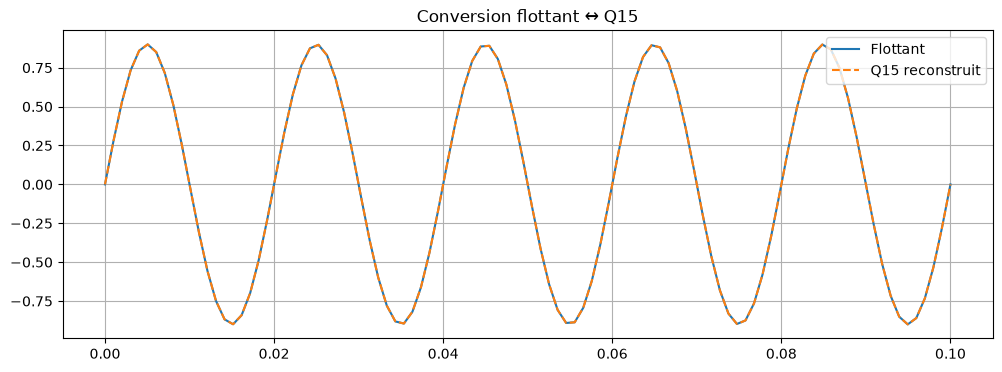

In [2]:
def float_to_q15(x):
    """Convertit un flottant (dans [-1, 1]) en entier Q15 (int16)."""
    x_sat = np.clip(x, -1.0, 1.0)
    return np.round(x_sat * 32767).astype(np.int16)

def q15_to_float(x_q):
    """Convertit un entier Q15 (int16) en flottant."""
    return x_q.astype(np.float32) / 32767.0

# Exemple
t = np.linspace(0, 0.1, 100)
signal_float = 0.9 * np.sin(2*np.pi*50*t)

signal_q15 = float_to_q15(signal_float)
signal_reconstruit = q15_to_float(signal_q15)

plt.figure(figsize=(12, 4))
plt.plot(t, signal_float, label='Flottant')
plt.plot(t, signal_reconstruit, '--', label='Q15 reconstruit')
plt.legend()
plt.grid()
plt.title('Conversion flottant ↔ Q15')
plt.show()

## 2.2 Filtre FIR en Q15 (simulation de arm_fir_q15)

Nous allons simuler un filtre FIR en utilisant des opérations Q15. La fonction `arm_fir_q15` utilise des accumulateurs en Q31 pour éviter les débordements.

C:\Users\hp\AppData\Local\Temp\ipykernel_11320\3077985749.py:19: RuntimeWarning: overflow encountered in scalar add
  acc += np.int32(state[k]) * np.int32(b_q[k])


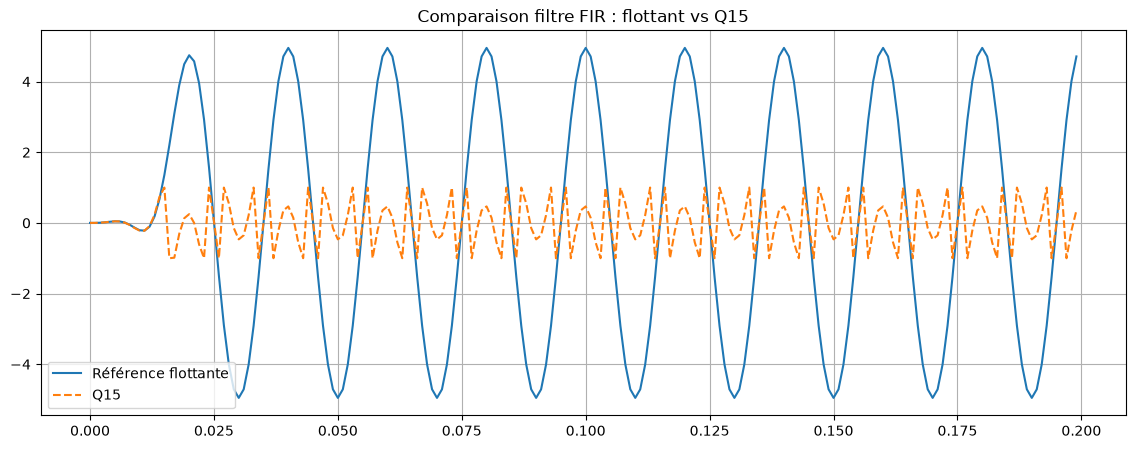

Erreur maximale : 4.574916


In [3]:
def fir_q15(x_q, b_q):
    """Simule un filtre FIR en Q15.
    x_q : entrée en Q15 (int16)
    b_q : coefficients en Q15 (int16)
    Retourne la sortie en Q15.
    """
    M = len(b_q)
    N = len(x_q)
    y_q = np.zeros(N, dtype=np.int16)
    # Buffer d'état (en Q15)
    state = np.zeros(M, dtype=np.int16)
    for n in range(N):
        # Mise à jour du buffer (décalage)
        state[1:] = state[:-1]
        state[0] = x_q[n]
        # Accumulateur en Q31 (32 bits) pour éviter les débordements
        acc = np.int32(0)
        for k in range(M):
            acc += np.int32(state[k]) * np.int32(b_q[k])
        # On décale de 15 pour repasser en Q15 (car produit de deux Q15 donne Q30, on ramène en Q15)
        # Attention : arrondi
        acc = (acc + (1 << 14)) >> 15
        # Saturation
        acc = np.clip(acc, -32768, 32767)
        y_q[n] = acc.astype(np.int16)
    return y_q

# Conception d'un filtre FIR passe-bas en flottant
fs = 1000
fc = 100
N_taps = 31
b_float = signal.firwin(N_taps, fc, fs=fs, window='hamming')

# Normalisation et conversion en Q15
b_float = b_float / np.max(np.abs(b_float))  # normalisation pour rester dans [-1, 1]
b_q15 = float_to_q15(b_float)

# Signal d'entrée en flottant et conversion Q15
t = np.linspace(0, 0.2, 200, endpoint=False)
x_float = np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*200*t)
x_q15 = float_to_q15(x_float)

# Filtrage en Q15
y_q15 = fir_q15(x_q15, b_q15)
y_float_reconstruit = q15_to_float(y_q15)

# Filtrage en flottant pour référence
y_float_ref = signal.lfilter(b_float, 1, x_float)

# Comparaison
plt.figure(figsize=(14, 5))
plt.plot(t, y_float_ref, label='Référence flottante')
plt.plot(t, y_float_reconstruit, '--', label='Q15')
plt.legend()
plt.grid()
plt.title('Comparaison filtre FIR : flottant vs Q15')
plt.show()

err = np.max(np.abs(y_float_ref - y_float_reconstruit))
print(f"Erreur maximale : {err:.6f}")

## 2.3 FFT en Q15 (simulation de arm_rfft_q15)

La FFT en Q15 nécessite une mise à l'échelle pour éviter les débordements. Nous allons simuler une FFT sur des données Q15 et comparer avec la FFT flottante.

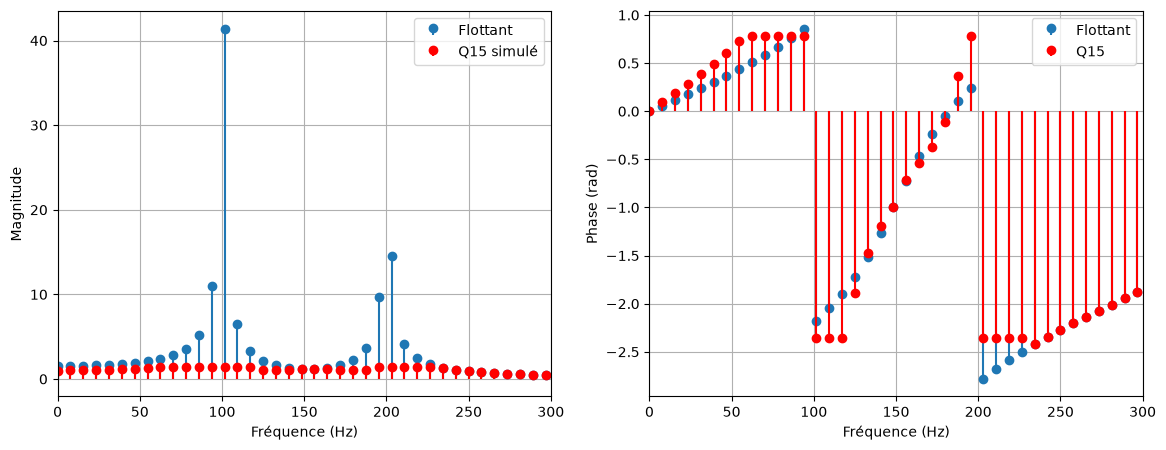

La version Q15 introduit une légère dégradation due à la quantification.


In [4]:
# Simulation d'une FFT en Q15
# Pour simplifier, on utilise la FFT flottante puis on quantifie les résultats en Q15
# Dans CMSIS-DSP, la FFT est implémentée en utilisant des rotations Q15 et des additions/soustractions avec saturation.

N_fft = 128
fs = 1000
t_fft = np.arange(N_fft) / fs
x_float = 0.7 * np.sin(2*np.pi*100*t_fft) + 0.3 * np.sin(2*np.pi*200*t_fft)

# FFT flottante
X_float = fft(x_float)[:N_fft//2]

# Conversion en Q15
x_q15 = float_to_q15(x_float)

# Simulation de la FFT Q15 : on effectue la FFT en flottant puis on quantifie les résultats
# Dans la réalité, la FFT Q15 utilise des étapes de mise à l'échelle.
X_q15_float = fft(q15_to_float(x_q15))[:N_fft//2]
# On quantifie les résultats en Q15 pour simuler la sortie de arm_rfft_q15
# La sortie de arm_rfft_q15 est généralement en Q15 pour la partie réelle et imaginaire.
X_q15_real = float_to_q15(np.real(X_q15_float))
X_q15_imag = float_to_q15(np.imag(X_q15_float))
X_q15 = q15_to_float(X_q15_real) + 1j * q15_to_float(X_q15_imag)

freqs = fftfreq(N_fft, 1/fs)[:N_fft//2]

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.stem(freqs, np.abs(X_float), basefmt=' ', label='Flottant')
plt.stem(freqs, np.abs(X_q15), linefmt='r-', markerfmt='ro', basefmt=' ', label='Q15 simulé')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Magnitude')
plt.xlim(0, 300)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.stem(freqs, np.angle(X_float), basefmt=' ', label='Flottant')
plt.stem(freqs, np.angle(X_q15), linefmt='r-', markerfmt='ro', basefmt=' ', label='Q15')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.show()

print("La version Q15 introduit une légère dégradation due à la quantification.")

## 2.4 Fonctions mathématiques (sin, cos, atan2) en Q15

CMSIS‑DSP fournit des tables de recherche pour les fonctions trigonométriques en Q15. Simulons un calcul de sinus en Q15 à l'aide d'une table.

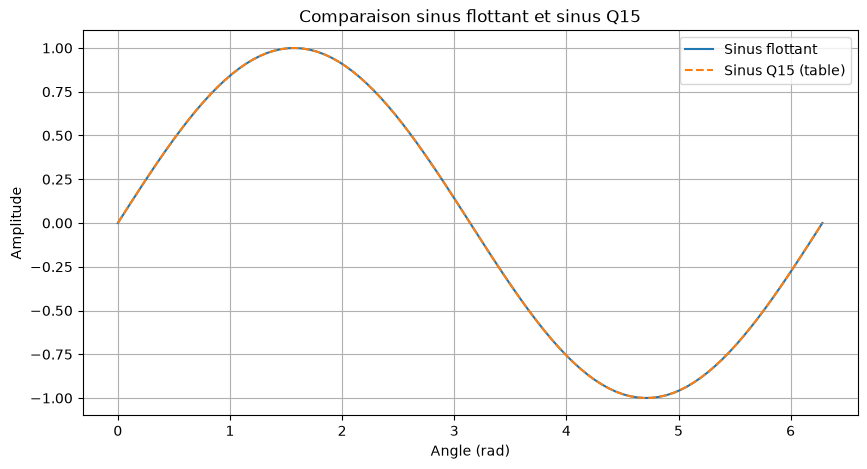

In [6]:

import numpy as np
import matplotlib.pyplot as plt

# Conversion float vers Q15
def float_to_q15(value):
    value = np.clip(value, -1.0, 1.0 - 1/32768)
    return np.int16(np.round(value * 32768))

# Conversion Q15 vers float
def q15_to_float(value):
    return np.asarray(value, dtype=np.float64) / 32768.0

# Fonction sinus avec table Q15
def sin_q15(angle_q15):
    n_points = 256

    # Table sinus
    table = np.sin(2 * np.pi * np.arange(n_points) / n_points)

    # Index et interpolation
    position = (int(angle_q15) % 32768) * n_points / 32768.0

    idx = int(position) % n_points
    frac = position - int(position)

    val = (1 - frac) * table[idx] + frac * table[(idx + 1) % n_points]

    return float_to_q15(val)

# Test
angles = np.linspace(0, 2*np.pi, 100)

sin_float = np.sin(angles)

# Conversion angle en représentation Q15 de 0 à 2*pi
angles_q15 = np.round(angles / (2*np.pi) * 32768).astype(np.int32) % 32768

sin_q15_vals = np.array([sin_q15(a) for a in angles_q15])

sin_reconst = q15_to_float(sin_q15_vals)

# Affichage
plt.figure(figsize=(10, 5))
plt.plot(angles, sin_float, label="Sinus flottant")
plt.plot(angles, sin_reconst, "--", label="Sinus Q15 (table)")

plt.xlabel("Angle (rad)")
plt.ylabel("Amplitude")
plt.title("Comparaison sinus flottant et sinus Q15")
plt.legend()
plt.grid()
plt.show()


# 3. Atelier : Mise en œuvre d'une application DSP embarquée

Nous allons simuler une application complète : un filtre anti-repliement (passe-bas) suivi d'une FFT pour analyser un signal, en utilisant des fonctions en virgule fixe. L'architecture est typique d'un système embarqué temps réel : acquisition (ADC), filtrage, FFT, puis communication ou affichage.

C:\Users\hp\AppData\Local\Temp\ipykernel_11320\3077985749.py:19: RuntimeWarning: overflow encountered in scalar add
  acc += np.int32(state[k]) * np.int32(b_q[k])


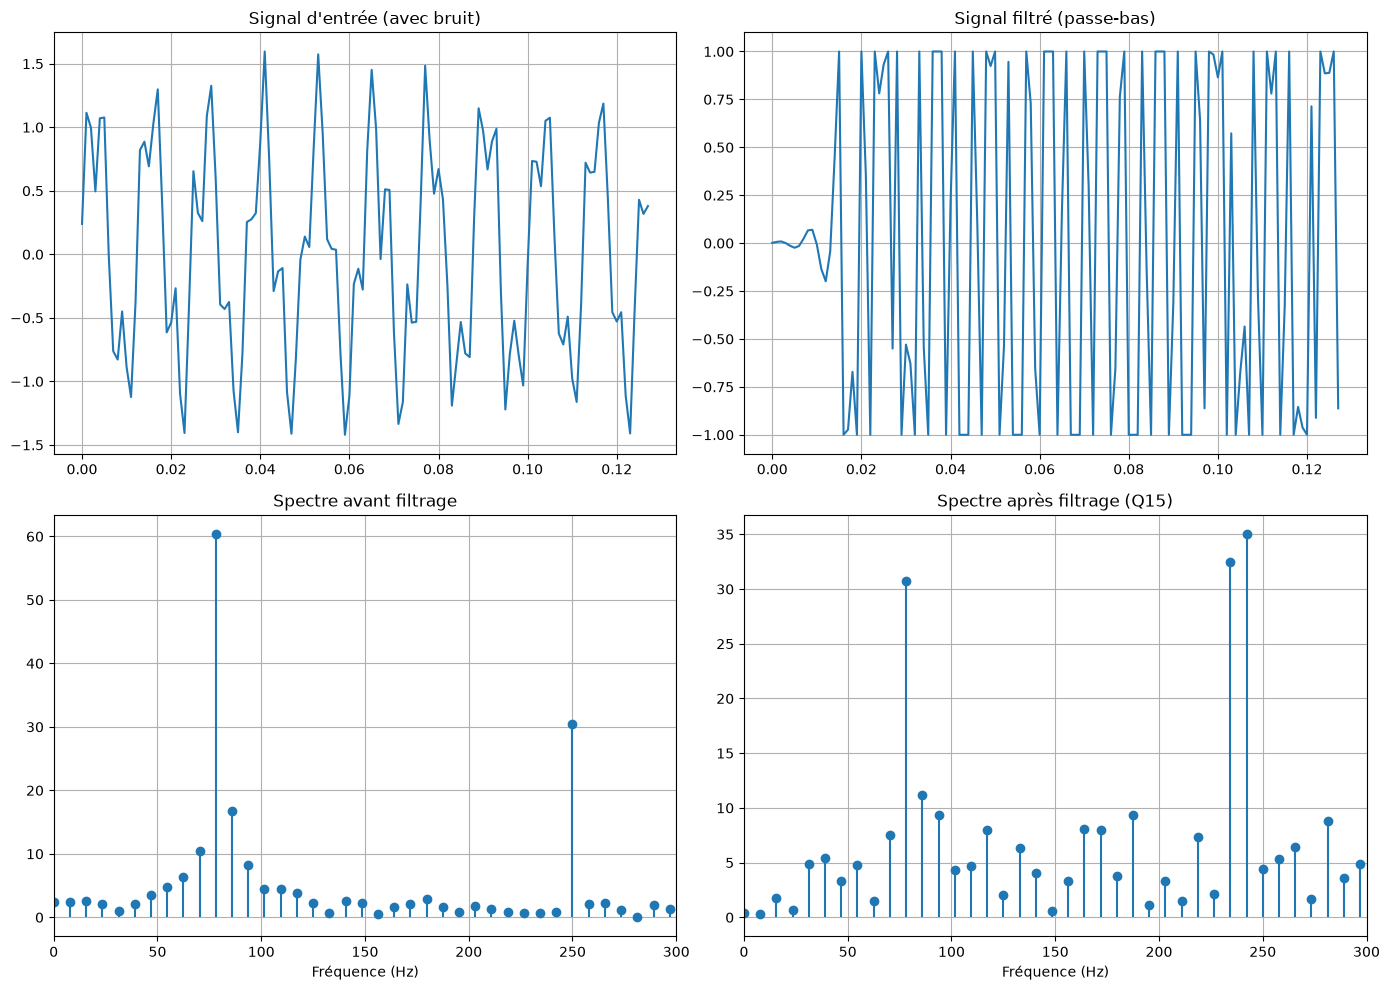

Taille du filtre : 31 coefficients en Q15
Nombre d'échantillons FFT : 128
En pratique, ces opérations peuvent être réalisées par CMSIS-DSP sur un Cortex-M4 en temps réel.


In [7]:
# Paramètres système
fs = 1000
N_samples = 128
t = np.arange(N_samples) / fs

# Signal d'entrée simulé (mélange de fréquences)
x_float = np.sin(2*np.pi*80*t) + 0.5*np.sin(2*np.pi*250*t) + 0.1*np.random.randn(N_samples)

# 1. Filtre anti-repliement (passe-bas en Q15)
# Conception du filtre en flottant
fc = 150
b_float = signal.firwin(31, fc, fs=fs, window='hamming')
b_float = b_float / np.max(np.abs(b_float))
b_q15 = float_to_q15(b_float)

# Conversion entrée en Q15
x_q15 = float_to_q15(x_float)

# Filtrage
y_q15 = fir_q15(x_q15, b_q15)
y_float = q15_to_float(y_q15)

# 2. FFT en Q15 sur le signal filtré
# (simulée comme précédemment)
X_q15_real = float_to_q15(np.real(fft(y_float)[:N_samples//2]))
X_q15_imag = float_to_q15(np.imag(fft(y_float)[:N_samples//2]))
X_q15 = q15_to_float(X_q15_real) + 1j*q15_to_float(X_q15_imag)

freqs = fftfreq(N_samples, 1/fs)[:N_samples//2]

# Visualisation
plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1)
plt.plot(t, x_float)
plt.title('Signal d\'entrée (avec bruit)')
plt.grid()

plt.subplot(2, 2, 2)
plt.plot(t, y_float)
plt.title('Signal filtré (passe-bas)')
plt.grid()

plt.subplot(2, 2, 3)
plt.stem(freqs, np.abs(fft(x_float)[:N_samples//2]), basefmt=' ')
plt.title('Spectre avant filtrage')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 300)
plt.grid()

plt.subplot(2, 2, 4)
plt.stem(freqs, np.abs(fft(y_float)[:N_samples//2]), basefmt=' ')
plt.title('Spectre après filtrage (Q15)')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 300)
plt.grid()

plt.tight_layout()
plt.show()

# Bilan des ressources simulées
print(f"Taille du filtre : {len(b_q15)} coefficients en Q15")
print(f"Nombre d'échantillons FFT : {N_samples}")
print("En pratique, ces opérations peuvent être réalisées par CMSIS-DSP sur un Cortex-M4 en temps réel.")

# 4. Exercices – Semaine 11

## Exercice 1 – Filtre RII en Q15

1. Concevoir un filtre RII Butterworth passe-bas d'ordre 4 avec fc=100 Hz, fs=1000 Hz.
2. Convertir les coefficients en Q15 (normalisation puis quantification).
3. Implémenter une fonction `iir_q15` simulant un filtre RII en Q15 (structure directe II) en utilisant un accumulateur Q31.
4. Tester sur un signal bruité et comparer avec la version flottante.
5. Discuter de la stabilité : que se passe-t-il si l'ordre est trop élevé en Q15 ?

**Code** :

Coefficients flottants :
b = [0.00482434 0.01929737 0.02894606 0.01929737 0.00482434]
a = [ 1.         -2.36951301  2.31398841 -1.05466541  0.18737949]

Coefficients quantifiés :
b_q = [158 632 949 632 158]
a_q = [ 32768 -77644  75825 -34559   6140]


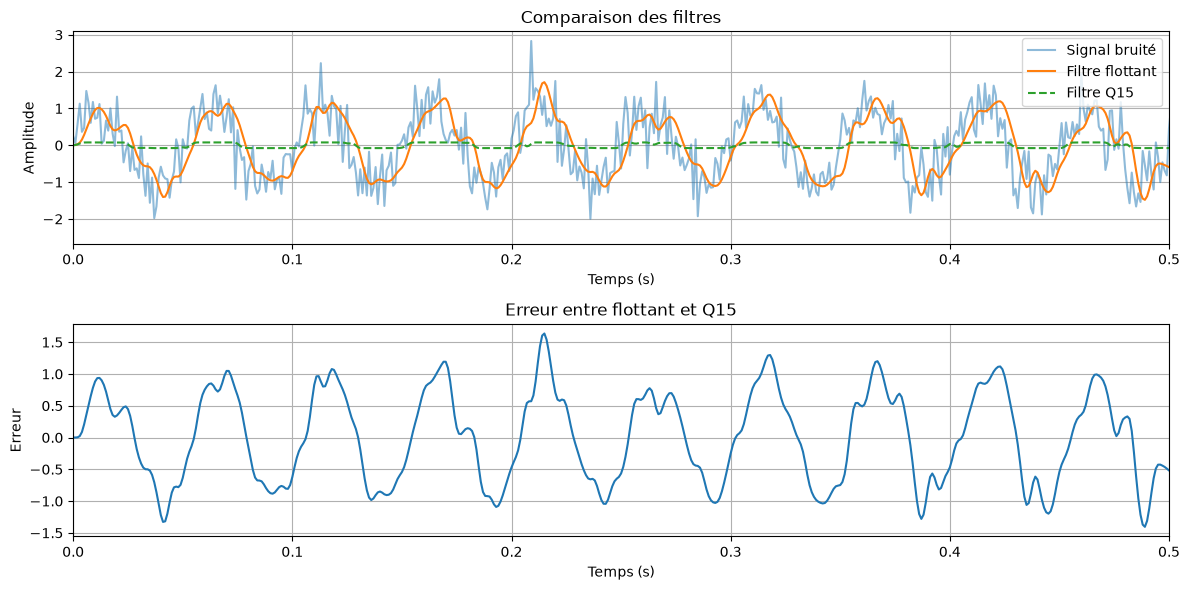

Erreur quadratique moyenne : 0.49097176612460586

Stabilité du filtre :
Filtre flottant stable : True
Filtre Q15 stable : True

Modules des pôles Q15 :
[0.79551237 0.79551237 0.54414204 0.54414204]


In [8]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# ==========================================
# 1. CONCEPTION DU FILTRE BUTTERWORTH
# ==========================================

fs = 1000
fc = 100
ordre = 4

b, a = signal.butter(ordre, fc, btype='low', fs=fs)

# Normalisation des coefficients
b = b / a[0]
a = a / a[0]

print("Coefficients flottants :")
print("b =", b)
print("a =", a)


# ==========================================
# 2. CONVERSION DES COEFFICIENTS EN Q15
# ==========================================

Q15 = 32768

def quantize_q15(coeffs):
    return np.round(coeffs * Q15).astype(np.int32)

b_q = quantize_q15(b)
a_q = quantize_q15(a)

# a[0] = 1 exactement en représentation Q15 étendue
a_q[0] = Q15

print("\nCoefficients quantifiés :")
print("b_q =", b_q)
print("a_q =", a_q)


# ==========================================
# 3. IMPLEMENTATION DU FILTRE RII Q15
# Structure directe II avec accumulateur Q31
# ==========================================

def saturate_q15(value):
    return max(-32768, min(32767, int(value)))

def saturate_q31(value):
    return max(-(2**31), min(2**31 - 1, int(value)))

def iir_q15(x_q, b_q, a_q):

    N = len(x_q)
    nb = len(b_q) - 1
    na = len(a_q) - 1

    # Etats internes
    w = np.zeros(max(nb, na) + 1, dtype=np.int32)

    y_q = np.zeros(N, dtype=np.int32)

    for n in range(N):

        # Calcul de w[n]
        acc = int(x_q[n]) * Q15

        for i in range(1, na + 1):
            acc -= int(a_q[i]) * int(w[i])

        # Conversion Q30 vers Q15
        acc = saturate_q31(acc << 1)
        w[0] = saturate_q15(acc >> 16)

        # Calcul de la sortie y[n]
        acc_y = 0

        for i in range(nb + 1):
            acc_y += int(b_q[i]) * int(w[i])

        # Accumulateur Q31
        acc_y = saturate_q31(acc_y << 1)

        y_q[n] = saturate_q15(acc_y >> 16)

        # Décalage des états
        for i in range(max(nb, na), 0, -1):
            w[i] = w[i-1]

    return y_q


# ==========================================
# 4. TEST SUR UN SIGNAL BRUITE
# ==========================================

np.random.seed(42)

t = np.arange(2000) / fs

# Signal utile à 20 Hz
x = np.sin(2 * np.pi * 20 * t)

# Ajout du bruit
noise = 0.5 * np.random.randn(len(t))
x_noisy = x + noise

# Filtrage flottant
y_float = signal.lfilter(b, a, x_noisy)

# Conversion du signal en Q15
x_q = quantize_q15(x_noisy)

# Filtrage Q15
y_q = iir_q15(x_q, b_q, a_q)

# Retour en flottant
y_q_float = y_q / Q15


# ==========================================
# 5. COMPARAISON DES RESULTATS
# ==========================================

plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(t, x_noisy, label="Signal bruité", alpha=0.5)
plt.plot(t, y_float, label="Filtre flottant")
plt.plot(t, y_q_float, '--', label="Filtre Q15")
plt.xlim(0, 0.5)
plt.xlabel("Temps (s)")
plt.ylabel("Amplitude")
plt.title("Comparaison des filtres")
plt.legend()
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(t, y_float - y_q_float)
plt.xlim(0, 0.5)
plt.xlabel("Temps (s)")
plt.ylabel("Erreur")
plt.title("Erreur entre flottant et Q15")
plt.grid()

plt.tight_layout()
plt.show()


# ==========================================
# 6. CALCUL DE L'ERREUR
# ==========================================

mse = np.mean((y_float - y_q_float)**2)

print("Erreur quadratique moyenne :", mse)


# ==========================================
# 7. VERIFICATION DE LA STABILITE
# ==========================================

poles_float = np.roots(a)
poles_q15 = np.roots(a_q / Q15)

stable_float = np.all(np.abs(poles_float) < 1)
stable_q15 = np.all(np.abs(poles_q15) < 1)

print("\nStabilité du filtre :")
print("Filtre flottant stable :", stable_float)
print("Filtre Q15 stable :", stable_q15)

print("\nModules des pôles Q15 :")
print(np.abs(poles_q15))


## Exercice 2 – FFT en Q15 et fenêtrage

1. Générer un signal composé de deux sinusoïdes de fréquences 120 Hz et 130 Hz, fs=1000 Hz, N=64.
2. Appliquer une fenêtre de Hamming en Q15 (convertir la fenêtre en Q15).
3. Calculer la FFT en Q15 (simulée) et tracer le spectre.
4. Comparer la résolution spectrale avec et sans fenêtre.

**Code** :

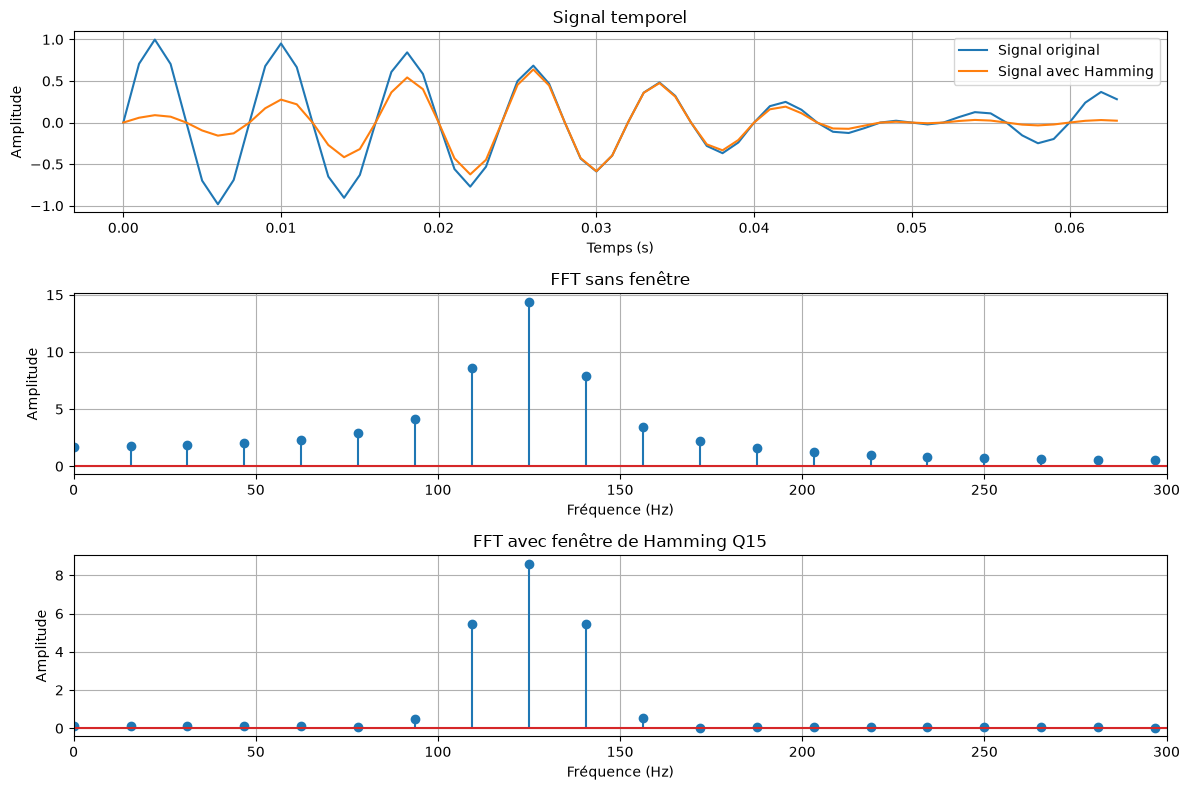

Résolution spectrale : 15.625 Hz
Fréquence du premier sinus : 120 Hz
Fréquence du deuxième sinus : 130 Hz

Comparaison :
Sans fenêtre : fuite spectrale importante.
Avec Hamming : réduction des lobes secondaires.
La fenêtre Hamming élargit légèrement le lobe principal.


In [9]:
# À compléter

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. GENERATION DU SIGNAL
# ==========================================

fs = 1000
N = 64

t = np.arange(N) / fs

# Deux sinusoïdes : 120 Hz et 130 Hz
x = (0.5 * np.sin(2*np.pi*120*t)
     + 0.5 * np.sin(2*np.pi*130*t))

# ==========================================
# 2. CONVERSION EN Q15
# ==========================================

Q15 = 32768

def float_to_q15(x):
    x = np.clip(x, -1.0, 1.0 - 1/Q15)
    return np.round(x * Q15).astype(np.int16)

def q15_to_float(x):
    return np.asarray(x, dtype=float) / Q15

x_q15 = float_to_q15(x)

# ==========================================
# 3. FENETRE DE HAMMING EN Q15
# ==========================================

window = np.hamming(N)

window_q15 = float_to_q15(window)

# Application de la fenêtre en Q15
x_window_q15 = (
    (x_q15.astype(np.int32) *
     window_q15.astype(np.int32)) >> 15
).astype(np.int16)

# Retour en flottant
x_window = q15_to_float(x_window_q15)

# ==========================================
# 4. FFT Q15 SIMULEE
# ==========================================

# Simulation de la FFT avec quantification Q15
def fft_q15(x_q15):
    x_float = q15_to_float(x_q15)

    # Calcul FFT
    X = np.fft.fft(x_float)

    # Quantification des parties réelle et imaginaire
    real_q15 = float_to_q15(np.real(X) / N)
    imag_q15 = float_to_q15(np.imag(X) / N)

    X_q15 = (
        real_q15.astype(float)
        + 1j * imag_q15.astype(float)
    ) * N / Q15

    return X_q15

# FFT sans fenêtre
X_no_window = fft_q15(x_q15)

# FFT avec fenêtre
X_window = fft_q15(x_window_q15)

# ==========================================
# 5. CALCUL DU SPECTRE
# ==========================================

freqs = np.fft.fftfreq(N, 1/fs)

# Partie positive du spectre
positive = freqs >= 0

freqs_pos = freqs[positive]

spectrum_no_window = np.abs(X_no_window[positive])
spectrum_window = np.abs(X_window[positive])

# ==========================================
# 6. AFFICHAGE DES RESULTATS
# ==========================================

plt.figure(figsize=(12, 8))

# Signal temporel
plt.subplot(3, 1, 1)
plt.plot(t, x, label="Signal original")
plt.plot(t, x_window, label="Signal avec Hamming")
plt.xlabel("Temps (s)")
plt.ylabel("Amplitude")
plt.title("Signal temporel")
plt.legend()
plt.grid()

# Spectre sans fenêtre
plt.subplot(3, 1, 2)
plt.stem(freqs_pos, spectrum_no_window)
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude")
plt.title("FFT sans fenêtre")
plt.xlim(0, 300)
plt.grid()

# Spectre avec fenêtre
plt.subplot(3, 1, 3)
plt.stem(freqs_pos, spectrum_window)
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude")
plt.title("FFT avec fenêtre de Hamming Q15")
plt.xlim(0, 300)
plt.grid()

plt.tight_layout()
plt.show()

# ==========================================
# 7. RESOLUTION SPECTRALE
# ==========================================

resolution = fs / N

print("Résolution spectrale :", resolution, "Hz")
print("Fréquence du premier sinus : 120 Hz")
print("Fréquence du deuxième sinus : 130 Hz")

print("\nComparaison :")
print("Sans fenêtre : fuite spectrale importante.")
print("Avec Hamming : réduction des lobes secondaires.")
print("La fenêtre Hamming élargit légèrement le lobe principal.")


## Exercice 3 – Estimation de la consommation mémoire

Pour une application DSP embarquée, on doit estimer la mémoire nécessaire.

1. Un filtre FIR à 64 coefficients en Q15 (int16) est utilisé. Calculer la mémoire pour les coefficients, l'état (buffer circulaire), et le code si nécessaire.
2. Une FFT de 256 points en Q15 nécessite des tables de twiddle factors (rotations). Estimer la mémoire pour ces tables.
3. Proposer une optimisation pour réduire la mémoire (par exemple, utiliser des coefficients symétriques pour le FIR).

**Réponse** :
- Coefficients : 64 * 2 octets = 128 octets.
- Buffer d'état : 64 * 2 = 128 octets.
- Tables FFT (twiddle) : pour N=256, environ N/2 * 2 = 256 octets en Q15.
- Total : environ 512 octets, plus le code. On peut réduire en utilisant la symétrie pour le FIR (coefficients symétriques) ce qui permet de stocker la moitié des coefficients et d'utiliser une structure optimisée.

## Exercice 4 – Proposition de projet final

Rédiger une proposition de projet intégrant du DSP sur STM32 avec CMSIS‑DSP. La proposition doit inclure :
- Objectif du projet (ex : analyse de signaux ECG, traitement audio, contrôle moteur).
- Spécifications techniques (fréquence d'échantillonnage, nombre de canaux, type de traitement).
- Choix des algorithmes (filtres, FFT, etc.) et justification.
- Estimation des ressources (temps de calcul, mémoire).
- Plan de développement.

**Rédiger la proposition dans une cellule Markdown.**

## Exercice 5 – Simulation d'une application temps réel

On souhaite simuler un traitement temps réel sur un microcontrôleur. On considère un buffer circulaire de 128 échantillons, un filtre FIR de 31 coefficients, et une FFT de 128 points.

1. Écrire un code Python qui simule le traitement en continu : chaque itération, on ajoute un nouvel échantillon, on met à jour le buffer, on applique le filtre et on calcule la FFT sur les 128 derniers échantillons.
2. Mesurer le temps d'exécution de chaque étape (utiliser `time.perf_counter`).
3. Estimer si un Cortex-M4 à 100 MHz peut respecter une période d'échantillonnage de 1 ms.
4. Proposer des optimisations (ex : utiliser la FFT uniquement tous les N échantillons).

**Code** :

Temps moyen de mise à jour du buffer : 1.347479410469532 µs
Temps moyen du filtre FIR : 129.68146707862616 µs
Temps moyen de la FFT : 66.8096368851727 µs
Temps moyen total par itération : 161.7205422371626 µs

Période d'échantillonnage : 1.0 ms
Temps moyen : 0.1617205422371626 ms
Temps maximum : 7.920700125396252 ms
Le traitement dépasse la période en simulation Python.

Temps moyen avec optimisation : 0.004952466115355492 ms


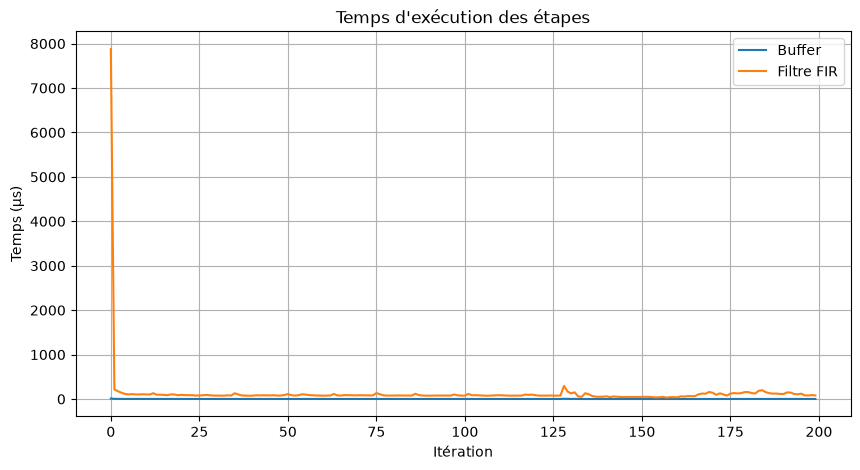

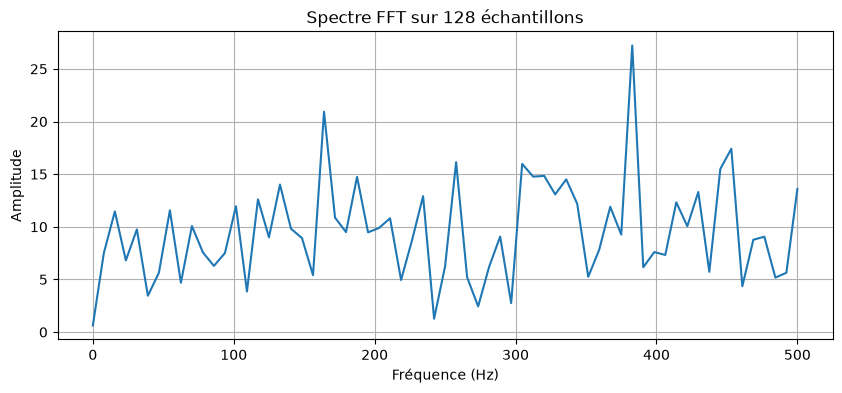

In [10]:

import numpy as np
import time
import matplotlib.pyplot as plt
from scipy import signal

# ==========================================
# 1. INITIALISATION
# ==========================================

buffer_size = 128
num_taps = 31
fs = 1000
N = 128

# Buffer circulaire
buffer = np.zeros(buffer_size)
write_index = 0

# Filtre FIR passe-bas
fc = 100
b = signal.firwin(num_taps, fc, fs=fs)

# Etat du filtre FIR
zi = np.zeros(num_taps - 1)

# Mesures du temps
time_buffer = []
time_filter = []
time_fft = []
time_total = []

# Résultats
fft_results = []

# Simulation
np.random.seed(42)
num_samples = 200

# ==========================================
# 2. TRAITEMENT EN CONTINU
# ==========================================

for n in range(num_samples):

    start_total = time.perf_counter()

    # Nouvel échantillon simulé
    new_sample = np.random.randn()

    # --------------------------------------
    # Mise à jour du buffer circulaire
    # --------------------------------------
    t1 = time.perf_counter()

    buffer[write_index] = new_sample
    write_index = (write_index + 1) % buffer_size

    t2 = time.perf_counter()

    # --------------------------------------
    # Filtrage FIR
    # --------------------------------------
    t3 = time.perf_counter()

    y, zi = signal.lfilter(
        b, 1.0, [new_sample], zi=zi
    )

    filtered_sample = y[0]

    t4 = time.perf_counter()

    # --------------------------------------
    # FFT sur les 128 derniers échantillons
    # --------------------------------------
    if n >= buffer_size - 1:

        t5 = time.perf_counter()

        # Réorganisation du buffer circulaire
        ordered_buffer = np.concatenate((
            buffer[write_index:],
            buffer[:write_index]
        ))

        # Calcul FFT
        spectrum = np.fft.rfft(ordered_buffer, n=N)

        fft_results.append(np.abs(spectrum))

        t6 = time.perf_counter()

        time_fft.append(t6 - t5)

    else:
        t5 = time.perf_counter()
        t6 = t5

    # --------------------------------------
    # Mesure du temps
    # --------------------------------------
    end_total = time.perf_counter()

    time_buffer.append(t2 - t1)
    time_filter.append(t4 - t3)
    time_total.append(end_total - start_total)


# ==========================================
# 3. AFFICHAGE DES TEMPS D'EXECUTION
# ==========================================

print("Temps moyen de mise à jour du buffer :",
      np.mean(time_buffer) * 1e6, "µs")

print("Temps moyen du filtre FIR :",
      np.mean(time_filter) * 1e6, "µs")

print("Temps moyen de la FFT :",
      np.mean(time_fft) * 1e6, "µs")

print("Temps moyen total par itération :",
      np.mean(time_total) * 1e6, "µs")

# ==========================================
# 4. EVALUATION DU TEMPS REEL
# ==========================================

periode = 1e-3  # 1 ms

temps_moyen = np.mean(time_total)
temps_max = np.max(time_total)

print("\nPériode d'échantillonnage :", periode * 1000, "ms")
print("Temps moyen :", temps_moyen * 1000, "ms")
print("Temps maximum :", temps_max * 1000, "ms")

if temps_max < periode:
    print("Le traitement respecte la période en simulation Python.")
else:
    print("Le traitement dépasse la période en simulation Python.")

# ==========================================
# 5. OPTIMISATION : FFT TOUS LES 8 ECHANTILLONS
# ==========================================

fft_period = 8

buffer_opt = np.zeros(buffer_size)
index_opt = 0

time_opt = []

for n in range(num_samples):

    start = time.perf_counter()

    new_sample = np.random.randn()

    buffer_opt[index_opt] = new_sample
    index_opt = (index_opt + 1) % buffer_size

    # FFT uniquement tous les 8 échantillons
    if (n + 1) % fft_period == 0 and n >= buffer_size - 1:

        ordered = np.concatenate((
            buffer_opt[index_opt:],
            buffer_opt[:index_opt]
        ))

        spectrum_opt = np.fft.rfft(ordered)

    end = time.perf_counter()
    time_opt.append(end - start)

print("\nTemps moyen avec optimisation :",
      np.mean(time_opt) * 1000, "ms")

# ==========================================
# 6. VISUALISATION
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(np.array(time_buffer) * 1e6,
         label="Buffer")

plt.plot(np.array(time_filter) * 1e6,
         label="Filtre FIR")

plt.xlabel("Itération")
plt.ylabel("Temps (µs)")
plt.title("Temps d'exécution des étapes")
plt.legend()
plt.grid()
plt.show()

# Spectre FFT final
if len(fft_results) > 0:

    freqs = np.fft.rfftfreq(N, 1/fs)

    plt.figure(figsize=(10, 4))
    plt.plot(freqs, fft_results[-1])
    plt.xlabel("Fréquence (Hz)")
    plt.ylabel("Amplitude")
    plt.title("Spectre FFT sur 128 échantillons")
    plt.grid()
    plt.show()


# 5. Livrable Semaine 11

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Date de rendu** : à définir par l'enseignant.

---